# 03 · Segments and actions

From RFM scores to ten CRM segments: what each segment is worth, how it behaves, what it buys and where, what happens if we do
nothing, and what the autumn campaign does with each segment and how we will know whether it worked.

*Snapshot 2020-09-22 · money in CU (price × 590), gross demand · reads the built marts in `data/marts/` and `reports/metrics.json`*

## TL;DR

- **High value is concentrated and does not need discounts.** Champions are 14% of customers and 54% of 12-month revenue, and
  41.1K VIPs (1,000+ CU a year) alone bring in 28%. 83% of Champions buy again within 90 days with business-as-usual contact only, so they get
  early access, not coupons.
- **Two groups are drifting away: 89.8K At Risk and 61.7K Slipping Regulars.** Left alone, At Risk is expected to spend 3.7M CU in
  the next 90 days against 5.8M CU at its usual pace (gap 2.1M CU, scenarios 2.1M-2.4M CU). Most of that gap is natural slowdown:
  the plan expects about 45K CU of incremental revenue from At Risk (26K from content emails, the rest from a 10% offer test
  cell that is expected to lose money on its own), and we measure that number instead of promising the gap.
- **Online-only customers are not a problem to fix.** 483K active customers (49%) had no identified store purchase in the last
  12 months. Their higher spend at equal order counts is mostly basket size (70 vs 33 CU per order for the same
  omnichannel customers, before returns), and looking forward they come back slightly less often (64% vs 69% at 5-9 orders).
  Channel decides the message; we do not pay to push them into stores.
- **The plan is content-led.** The rollout costs 13.5K CU and is expected to return +53K CU net on planning assumptions (pessimistic +2.2K,
  optimistic +239K). Discounts run only in two test cells, expected to cost 21K CU net: the price of learning whether they pay. Budget ask
  61.9K CU.
- **Measurement:** the same 10% holdout in every audience. The campaign-wide read detects a lift of 0.51 pp against 0.84 pp
  expected, and both coupon cells are sized so that a "no" is informative. Final read on 2020-12-27.

## Question

> "The autumn campaign budget is limited. Who are the high-value customers to keep, who is about to churn and needs winning back,
> who only buys online and never visits a store? Give me segments, a recommendation per segment, and how we will measure the
> campaign." (CRM Manager)

The request breaks down into the five analysis questions agreed in `docs/01_request_and_scope.md`:

| # | Business question | Answered in |
|---|---|---|
| Q1 | Who is high value and must be kept? | 1 Segments, 2 Value tier |
| Q2 | Who is about to churn, and what happens if we do nothing? | 3 Backtest, 6 If we do nothing, 7 Migration |
| Q3 | Who only buys online, and does it matter? | 5 Channel |
| Q4 | What should each segment get? | 4 Category focus, 8 Campaign plan |
| Q5 | How do we measure the campaign? | 9 Measurement |

## Data

- **Source:** H&M Personalized Fashion Recommendations dataset (Kaggle, 2022): 31,788,324 item rows from 2018-09-20 to
  2020-09-22, 1,362,281 customers with at least one order (1,371,980 in the customer file).
- **Inputs:** the marts in `data/marts/` built by `python run.py` (SQL in `sql/`, Python steps in `src/rfm/analysis.py` and
  `src/rfm/campaign.py`) and the headline numbers in `reports/metrics.json`. This notebook only reads them; the DuckDB queries
  below are small look-ups on the same marts.
- **Definitions that change how the numbers read:**
  - Money is in **CU = price × 590**: every scaled price lands on a retail price point (9.99, 19.99, 14.99 ...); the currency is
    not disclosed. All revenue is **gross demand**: the data has no returns.
  - An **order** is one customer, one day, one channel. There is no order id, so same-day online orders collapse into one.
    Identical rows are extra units of the same item and are kept as a units column.
  - **Channel** 1 = store, 2 = online: channel 1 has no sales while stores were closed (2020-03-20 to 2020-05-05; reopened
    2020-05-06). Store purchases are only visible when the shopper identifies as a member.
  - **Snapshot** 2020-09-22. Frequency and Monetary are measured over the trailing 365 days.
  - **Review List:** 864 accounts with bulk or near-daily buying. They stay in every total but get no offers or paid media until
    CRM / retail ops have reviewed them; they move 0.5% of revenue.

In [1]:
from rfm import nbsetup; nbsetup.init()

import warnings

import numpy as np
import pandas as pd

from rfm import campaign as CP
from rfm import charts as C, data as D
from rfm.config import ROOT
from rfm.segments import SEGMENT_INFO, SEGMENT_ORDER
from rfm.sqlrun import query, run_sql_file

warnings.filterwarnings("ignore", message="The kopts argument is ignored")  # kaleido notice on every PNG export

M = D.metrics()
H, SEG, CAMP = M["headline"], M["segments"], M["campaign"]


def sql_section(path: str, start: str, end: str, back: int = 0) -> None:
    """Print a SQL file from the first line containing `start` (minus `back` lines) to the next line containing `end`."""
    lines = (ROOT / path).read_text().splitlines()
    i = next(k for k, line in enumerate(lines) if start in line) - back
    j = next(k for k in range(i, len(lines)) if end in lines[k])
    print(f"-- {path}, lines {i + 1}-{j + 1}")
    print("\n".join(lines[i:j + 1]))


def table(df: pd.DataFrame, formats: dict | None = None):
    """Display a frame without its index, with per-column formats; missing values as '-'."""
    return df.style.format(formats or {}, na_rep="-").hide(axis="index")

In [2]:
# Scope of the current snapshot, and a reconciliation of the segment profile mart against customer_rfm
scope = query("""
    SELECT segment, COUNT(*) AS customers, SUM(monetary_12m_cu) AS revenue_12m_cu,
           SUM((frequency_12m > 0)::INT) AS active_12m
    FROM 'data/marts/customer_rfm.parquet'
    WHERE snapshot_name = 'current'
    GROUP BY segment
""")
prof = D.mart("segment_profile")
recon = prof[["segment", "customers", "revenue_12m_cu"]].merge(scope, on="segment", suffixes=("_profile", "_rfm"))
assert len(recon) == 10 and (recon.customers_profile == recon.customers_rfm).all()
assert np.allclose(recon.revenue_12m_cu_profile, recon.revenue_12m_cu_rfm)

pd.Series({
    "Customers with an order, 2018-09-20 to 2020-09-22": f"{scope.customers.sum():,}",
    "Active in the 12 months to 2020-09-22": f"{int(scope.active_12m.sum()):,} ({scope.active_12m.sum() / scope.customers.sum():.1%})",
    "12-month revenue (gross demand)": D.fmt_cu(scope.revenue_12m_cu.sum()),
    "Email-reachable share of active customers (newsletter)": D.pct(M["data"]["pct_newsletter_active"]),
    "Review List accounts (kept in all totals)": f"{M['data']['review_list_customers']:,}",
}, name="2020-09-22").to_frame()

,2020-09-22
"Customers with an order, 2018-09-20 to 2020-09-22","1,362,281"
Active in the 12 months to 2020-09-22,"993,492 (72.9%)"
12-month revenue (gross demand),247.3M CU
Email-reachable share of active customers (newsletter),37.1%
Review List accounts (kept in all totals),864


## Method

1. **Segments** (`sql/05_customer_rfm.sql`). Fixed business thresholds, not quantiles: R 30 / 60 / 120 / 180 days (365+ days =
   Lost), F 1 / 2 / 3-4 / 5-9 / 10+ orders, M 50 / 100 / 200 / 400 CU. Ten groups, first matching rule wins (printed below).
   Two more axes sit next to the segment: a **value tier** on 12-month spend (VIP 1,000+ CU, High 400-999, Mid 200-399, Low < 200,
   None) and the **channel profile** of the last 12 months (online only / store only / omnichannel).
2. **Validation.** The same rules applied at 2019-09-22 (same season one year earlier) and 2020-06-24 (last quarter), using only
   what was known on each date; then what each segment actually did in the following 90 days.
3. **Category affinity.** A segment's share of revenue in a category divided by all customers' share, × 100, over the same window
   (last 12 months; Lost: two years).
4. **Channel.** Online only vs omnichannel vs store only compared at equal order counts, with the channel measured on the 12 months
   before each date. These are descriptive comparisons between customers, not experiments.
5. **If we do nothing.** Usual pace = 12-month revenue × 90/365. Expected = usual pace × the share of it that look-alike customers
   spent in the 90 days after 2019-09-22, computed per R × F × M × 12-month-channel cell and re-weighted to today's mix. Scenarios:
   the 2020-06-24 backtest, and a pessimistic case that takes the worse of the two backtests in every cell.
6. **Campaign economics** (`src/rfm/campaign.py`). Per arm, over 90 days: incremental buyers = customers assigned × assumed lift
   (intention-to-treat); an incremental buyer is worth one order at the audience's AOV; 40% contribution margin; a coupon is also
   used by half of the customers who would have bought anyway; email 0.01 CU, paid social 0.30 CU per targeted non-subscriber.
   **All lifts are planning assumptions** that the holdout test replaces with measurements.
7. **Measurement.** A 10% holdout in every audience; minimum detectable lift at 5% significance and 80% power.

The segment rules as the CRM tool will run them:

In [3]:
sql_section("sql/05_customer_rfm.sql", "THEN 'Review List'", "AS channel_12m", back=1)

-- sql/05_customer_rfm.sql, lines 169-189
        CASE
            WHEN d.is_excluded                                         THEN 'Review List'
            WHEN s.recency_days >= getvariable('lookback_days')        THEN 'Lost'
            WHEN s.tenure_days  <  getvariable('new_customer_days')    THEN 'New Customers'
            WHEN s.r_score >= 4 AND s.f_score >= 4 AND s.m_score >= 4  THEN 'Champions'
            WHEN s.r_score >= 4 AND s.f_score >= 4                     THEN 'Loyal'
            WHEN s.r_score  = 3 AND s.f_score >= 4                     THEN 'Slipping Regulars'
            WHEN s.r_score >= 4                                        THEN 'Potential Loyalists'
            WHEN s.r_score  = 3                                        THEN 'Needs Attention'
            WHEN s.f_score >= 3 OR s.m_score >= 4                      THEN 'At Risk'
            ELSE 'Hibernating'
        END                                                            AS segment,
        CASE WHEN s.

## Results

### 1. Ten segments: who they are and what they are worth

One row per segment at 2020-09-22. AOV = 12-month revenue / 12-month orders; *% online only* = no identified store purchase in the
last 12 months; *% email reach* = newsletter subscribers, the customers we can reach for free.

In [4]:
view = pd.DataFrame({
    "Segment": prof.segment,
    "In plain words": prof.segment.map(lambda s: SEGMENT_INFO[s]["plain"]),
    "Customers": prof.customers,
    "% customers": prof.pct_customers,
    "% 12m revenue": prof.pct_revenue_12m,
    "Orders (12m)": prof.avg_orders_12m,
    "AOV (CU)": prof.aov_12m_cu.fillna(prof.aov_2y_cu),
    "Spend per customer (12m, CU)": prof.avg_revenue_12m_cu,
    "Median days since last order": prof.median_recency_days,
    "% online only": prof.pct_online_only_12m.fillna(prof.pct_online_only_2y),
    "% email reach": prof.pct_newsletter,
    "% VIP": prof.pct_vip,
})
table(view, {"Customers": "{:,.0f}", "% customers": "{:.1%}", "% 12m revenue": "{:.1%}", "Orders (12m)": "{:.1f}",
             "AOV (CU)": "{:.1f}", "Spend per customer (12m, CU)": "{:,.0f}", "Median days since last order": "{:.0f}",
             "% online only": "{:.0%}", "% email reach": "{:.0%}", "% VIP": "{:.1%}"})

Segment,In plain words,Customers,% customers,% 12m revenue,Orders (12m),AOV (CU),"Spend per customer (12m, CU)",Median days since last order,% online only,% email reach,% VIP
Champions,"Bought in the last 60 days, 5+ orders and 200+ CU in the last 12 months","190,320",14.0%,54.1%,12.0,58.7,703,19,20%,47%,18.6%
Loyal,"Bought in the last 60 days, 5+ orders in 12 months, under 200 CU (frequent, small baskets)","33,612",2.5%,2.0%,6.2,23.8,148,26,12%,48%,0.0%
Slipping Regulars,"5+ orders in 12 months, but no order in the last 61-120 days","61,655",4.5%,10.4%,7.5,55.1,416,83,23%,44%,5.8%
Potential Loyalists,"Bought in the last 60 days, 1-4 orders in 12 months (not new)","124,517",9.1%,7.8%,2.7,56.8,154,28,44%,38%,0.3%
New Customers,First order within the last 90 days,"71,117",5.2%,2.0%,1.3,51.6,69,39,66%,33%,0.0%
Needs Attention,"Last order 61-120 days ago, 1-4 orders in 12 months","137,675",10.1%,7.1%,2.3,56.6,128,92,55%,37%,0.2%
At Risk,Last order 121-364 days ago but used to buy often (3+ orders) or a lot (200+ CU),"89,848",6.6%,9.5%,3.7,69.5,261,188,51%,35%,1.4%
Hibernating,"Last order 121-364 days ago, 1-2 orders and under 200 CU","284,069",20.9%,6.6%,1.2,46.6,57,239,71%,29%,0.0%
Lost,No order in the last 365 days,"368,604",27.1%,0.0%,0.0,55.4,0,559,58%,29%,0.0%
Review List,Bulk or near-daily buying pattern: no offers or paid media until reviewed,864,0.1%,0.5%,22.8,64.9,"1,479",69,41%,37%,34.8%


Lost has no 12-month orders, so its AOV and online-only share use the two-year history.

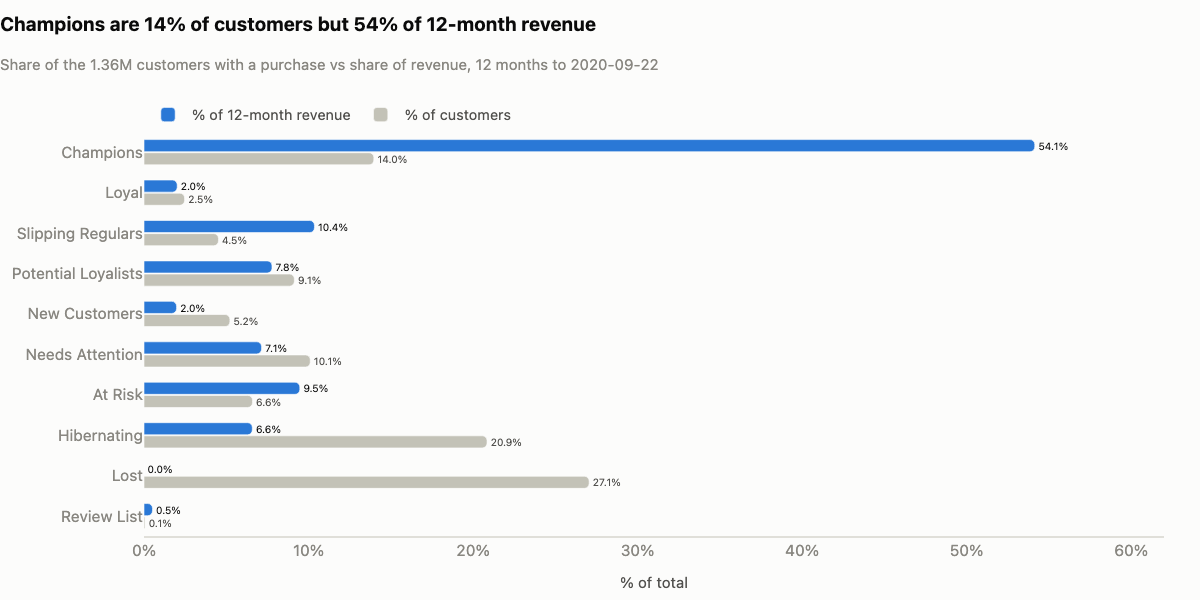

In [5]:
C.segment_share(prof)

**Takeaway:** Champions are 14% of customers and 54% of 12-month revenue; with Loyal and Slipping Regulars the frequent buyers are
21% of customers and 67% of revenue, while Hibernating and Lost are 48% of customers and 7% of revenue.

### 2. Value tier: a second axis

Rows are the lifecycle segments (what to do), columns the 12-month spend tier (how much effort a customer is worth). Each cell shows
customers and their share of all customers.

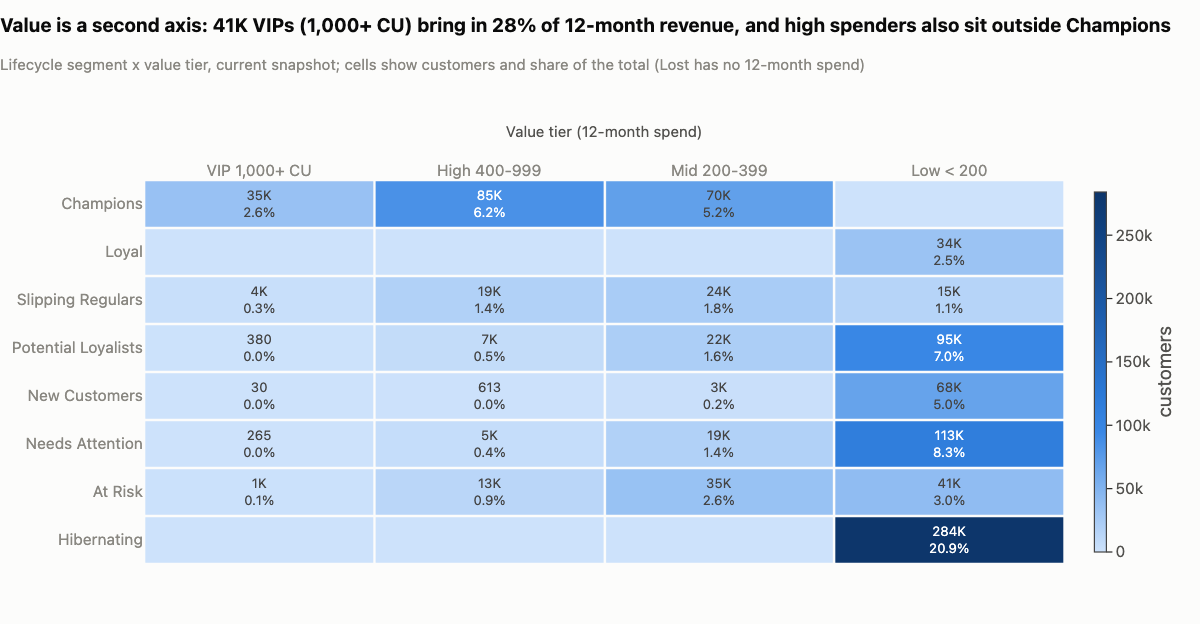

In [6]:
vg = D.mart("value_grid")
C.value_grid(vg)

**Takeaway:** 41.1K VIPs bring in 28% of 12-month revenue; 86% of them are Champions, but 3.5K sit in Slipping Regulars and 1.2K
in At Risk, which is why value, not only the segment name, decides who gets paid reach within At Risk (paid social only for the
long-lapsed customers spending 200+ CU).

In [7]:
vip = vg[vg.value_tier == "VIP"].set_index("segment").reindex(SEGMENT_ORDER).dropna(subset=["customers"]).reset_index()
vip = vip.assign(share_customers=vip.customers / vip.customers.sum(), share_revenue=vip.revenue_12m_cu / vip.revenue_12m_cu.sum())
table(vip[["segment", "customers", "share_customers", "revenue_12m_cu", "share_revenue"]].rename(columns={
          "segment": "Segment", "customers": "VIP customers", "share_customers": "% of VIPs",
          "revenue_12m_cu": "VIP 12-month revenue (CU)", "share_revenue": "% of VIP revenue"}),
      {"VIP customers": "{:,.0f}", "% of VIPs": "{:.1%}", "VIP 12-month revenue (CU)": "{:,.0f}", "% of VIP revenue": "{:.1%}"})

Segment,VIP customers,% of VIPs,VIP 12-month revenue (CU),% of VIP revenue
Champions,"35,366",86.0%,"60,187,098",87.3%
Slipping Regulars,"3,546",8.6%,"5,103,701",7.4%
Potential Loyalists,380,0.9%,"477,242",0.7%
New Customers,30,0.1%,"38,285",0.1%
Needs Attention,265,0.6%,"333,546",0.5%
At Risk,"1,230",3.0%,"1,648,820",2.4%
Review List,301,0.7%,"1,134,702",1.6%


### 3. Do the segments predict what customers do next? (backtest)

We pretend it is 2019-09-22 (blue) or 2020-06-24 (orange), put every customer in a segment using only what we knew then, and look at
how many bought again in the next 90 days. If the segments are useful, the bars line up from high to low at both dates.

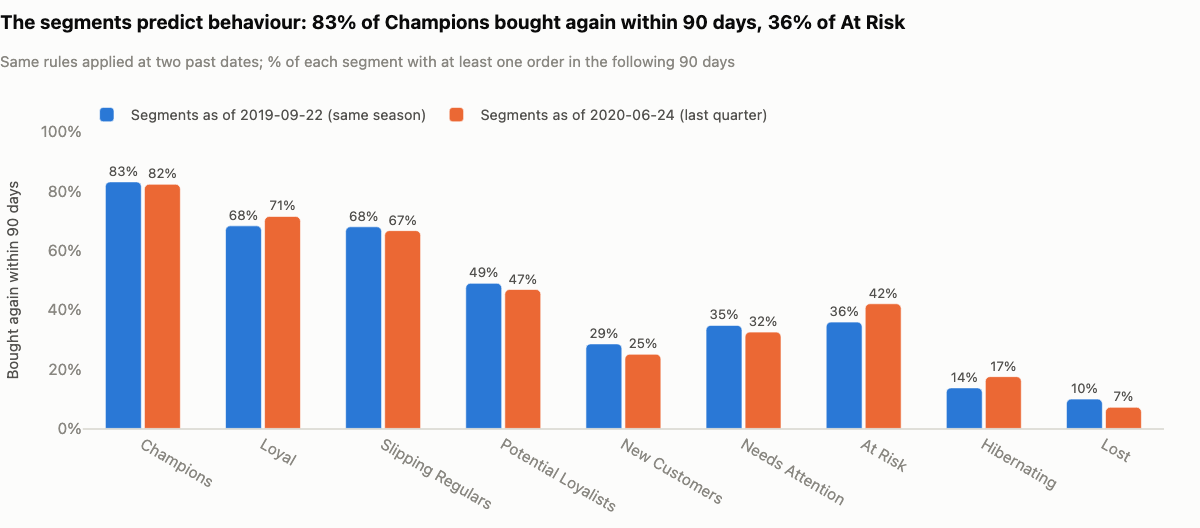

In [8]:
so = D.mart("segment_outcomes_90d")
C.segment_outcomes(so)

**Takeaway:** The order holds at both dates (Champions 83% / 82%, Loyal 68% / 71%, Slipping Regulars 68% / 67%, At Risk 36% / 42%,
Hibernating 14% / 17%), so the segments sort customers by what they do next, not only by what they did.

In [9]:
bt = so.pivot_table(index="segment", columns="snapshot_name", values=["customers", "repurchase_rate", "realisation_ratio"])
bt.columns = [f"{v} {s.replace('backtest_', '')}" for v, s in bt.columns]
bt = bt.reindex([s for s in SEGMENT_ORDER if s in bt.index]).reset_index()
table(bt[["segment", "customers seasonal", "repurchase_rate seasonal", "realisation_ratio seasonal",
          "customers recent", "repurchase_rate recent", "realisation_ratio recent"]].rename(columns={
          "segment": "Segment", "customers seasonal": "Customers 2019-09-22", "repurchase_rate seasonal": "Bought again in 90 days",
          "realisation_ratio seasonal": "Share of usual pace spent", "customers recent": "Customers 2020-06-24",
          "repurchase_rate recent": "Bought again in 90 days ", "realisation_ratio recent": "Share of usual pace spent "}),
      {"Customers 2019-09-22": "{:,.0f}", "Bought again in 90 days": "{:.1%}", "Share of usual pace spent": "{:.0%}",
       "Customers 2020-06-24": "{:,.0f}", "Bought again in 90 days ": "{:.1%}", "Share of usual pace spent ": "{:.0%}"})

Segment,Customers 2019-09-22,Bought again in 90 days,Share of usual pace spent,Customers 2020-06-24,Bought again in 90 days,Share of usual pace spent
Champions,"198,577",83.2%,89%,"190,987",82.4%,86%
Loyal,"32,988",68.3%,133%,"33,147",71.5%,135%
Slipping Regulars,"71,978",68.0%,84%,"47,146",66.7%,75%
Potential Loyalists,"81,749",48.9%,107%,"126,527",46.9%,104%
New Customers,"102,929",28.5%,137%,"101,219",25.0%,110%
Needs Attention,"118,164",34.8%,92%,"99,130",32.5%,87%
At Risk,"93,056",35.9%,64%,"115,618",42.0%,67%
Hibernating,"304,467",13.7%,75%,"275,061",17.5%,93%
Lost,"3,144",9.9%,-,"301,465",7.1%,-
Review List,761,60.4%,95%,847,53.0%,97%


Lost has only 3,144 customers at 2019-09-22 because the data starts a year earlier, so the plan takes Lost's business-as-usual
behaviour from the 2020-06-24 backtest.

### 4. What each segment buys: category affinity

Affinity index = the segment's share of revenue in a category / all customers' share × 100, same window on both sides. 100 = same as
everyone; blue bars over-index, red bars under-index. It reflects **when** a segment last bought as much as **what** it likes, so it
reads as "what to show them now", not as a fixed taste.

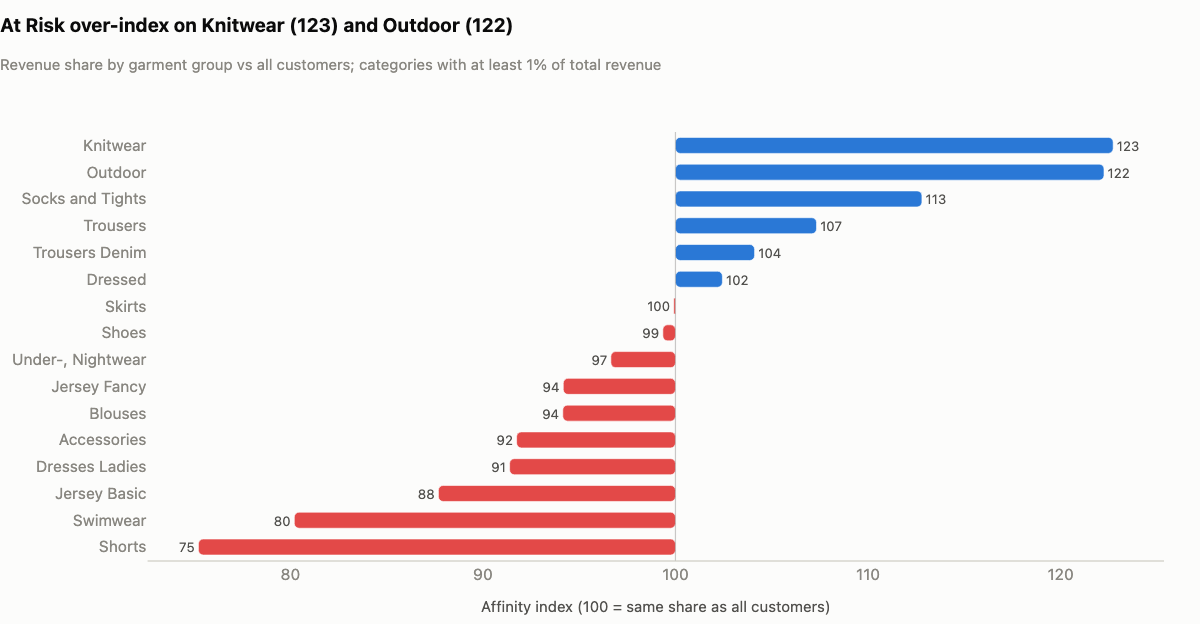

In [10]:
mix = D.mart("segment_mix")
C.category_affinity(mix, "At Risk")

**Takeaway:** At Risk over-index on knitwear (123) and outdoor (122): within the 12-month window they bought between September 2019
and May 2020, so the win-back creative leads with knitwear and outerwear (but see the split by recency below).

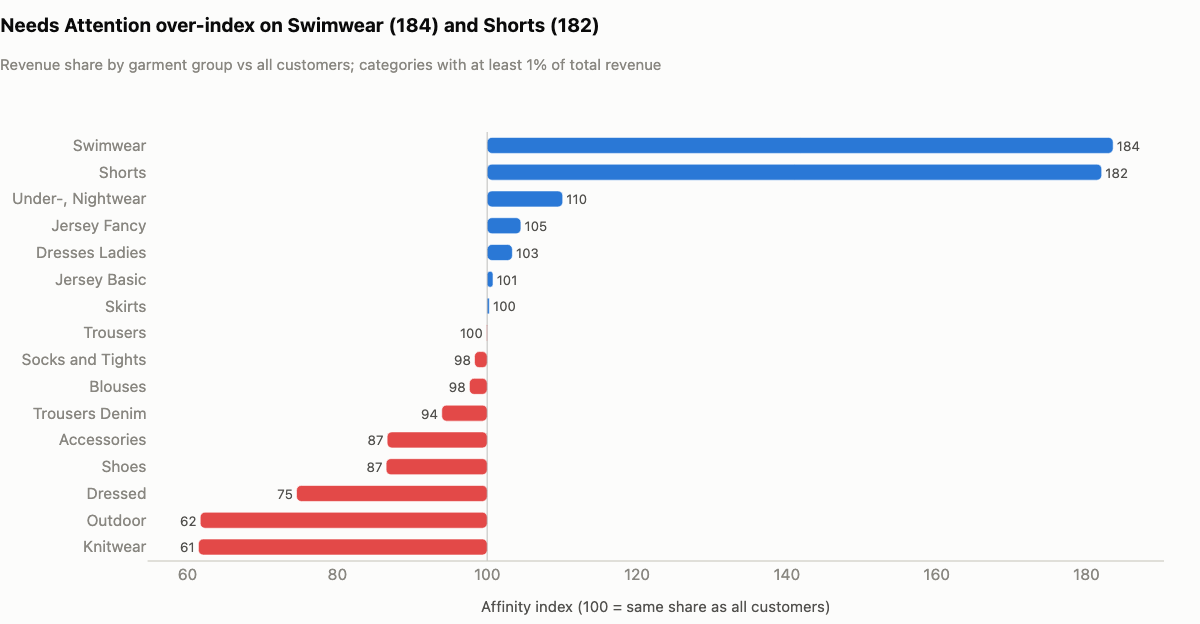

In [11]:
C.category_affinity(mix, "Needs Attention")

**Takeaway:** Needs Attention over-index on swimwear (184) and shorts (182) and under-index on knitwear (61): they last bought in
summer, so their edit bridges from summer buys to autumn basics.

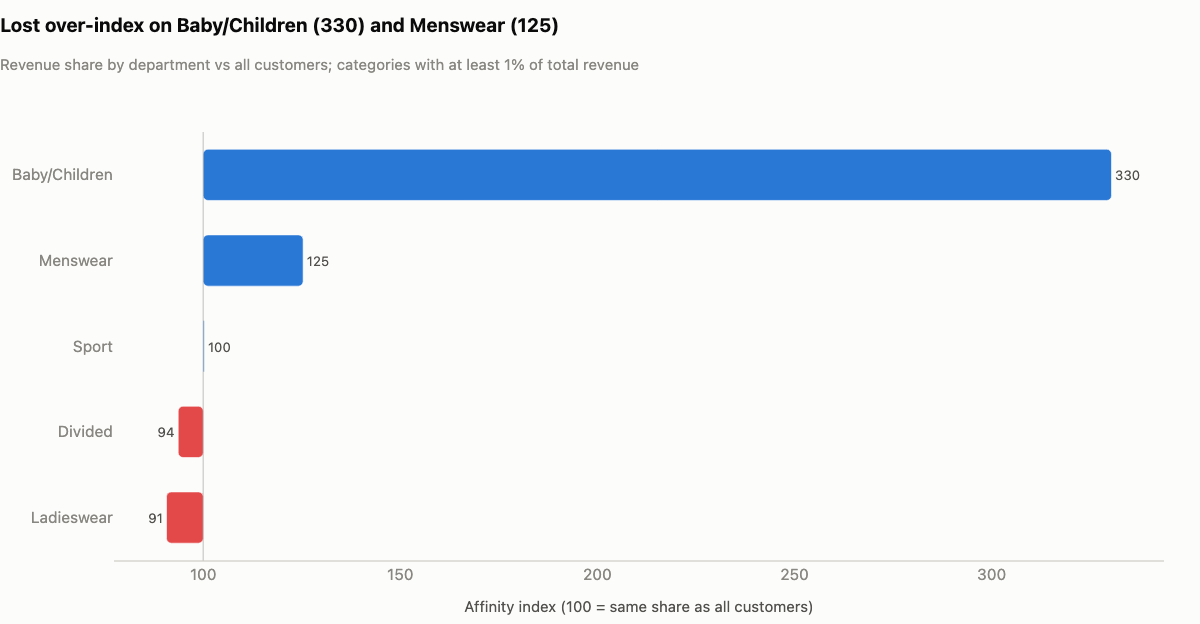

In [12]:
C.category_affinity(mix, "Lost", "index_group")

**Takeaway:** Over their two years Lost over-index on Baby/Children (330) and Menswear (125), the two departments the reactivation
email leads with; part of the kids' index is timing, checked in the look-up below.

In [13]:
# Lost customers only bought in the first year; compare their department mix with all customers in that same year
dept = query("""
    WITH cur AS (
        SELECT customer_id, segment FROM 'data/marts/customer_rfm.parquet'
        WHERE snapshot_name = 'current' AND segment <> 'Review List'
    ),
    lines AS (
        SELECT CASE WHEN DATE '2020-09-22' - l.order_date >= 365 THEN 'before the last 12 months' ELSE 'last 12 months' END AS period,
               c.segment = 'Lost' AS is_lost, a.index_group_name AS department, l.line_revenue_cents AS revenue
        FROM 'data/marts/fct_sales_lines.parquet' l
        JOIN cur c USING (customer_id)
        JOIN 'data/staged/stg_articles.parquet' a USING (article_id)
    ),
    g AS (
        SELECT period, department, SUM(revenue) AS rev_all, SUM(revenue) FILTER (WHERE is_lost) AS rev_lost
        FROM lines GROUP BY ALL
    )
    SELECT period, department, rev_all / SUM(rev_all) OVER (PARTITION BY period) AS share_all_customers,
           rev_lost / SUM(rev_lost) OVER (PARTITION BY period) AS share_lost
    FROM g
""")
first_year = dept[dept.period == "before the last 12 months"].assign(index_vs_same_year=lambda x: 100 * x.share_lost / x.share_all_customers)
last_12m = dept[dept.period == "last 12 months"].set_index("department")["share_all_customers"]
first_year = first_year.assign(share_all_last_12m=first_year.department.map(last_12m)).sort_values("index_vs_same_year", ascending=False)
table(first_year[["department", "share_lost", "share_all_customers", "index_vs_same_year", "share_all_last_12m"]].rename(columns={
          "department": "Department", "share_lost": "Lost: share of revenue", "share_all_customers": "All customers, same year",
          "index_vs_same_year": "Index vs same year", "share_all_last_12m": "All customers, last 12 months"}),
      {"Lost: share of revenue": "{:.1%}", "All customers, same year": "{:.1%}", "Index vs same year": "{:.0f}",
       "All customers, last 12 months": "{:.1%}"})

Department,Lost: share of revenue,"All customers, same year",Index vs same year,"All customers, last 12 months"
Baby/Children,8.8%,3.7%,238,1.5%
Menswear,6.9%,5.5%,126,5.6%
Sport,4.1%,3.8%,108,4.4%
Divided,20.1%,21.6%,93,21.2%
Ladieswear,60.2%,65.5%,92,67.4%


**Takeaway:** Lost customers bought when Baby/Children was 3.7% of all sales; in the last 12 months it is 1.5%. Against the same
year the kids' index is about 240 rather than 330, still a strong over-index, so kids' autumn stays the lead of the reactivation
email, provided the current kids' range is deep enough to carry it.

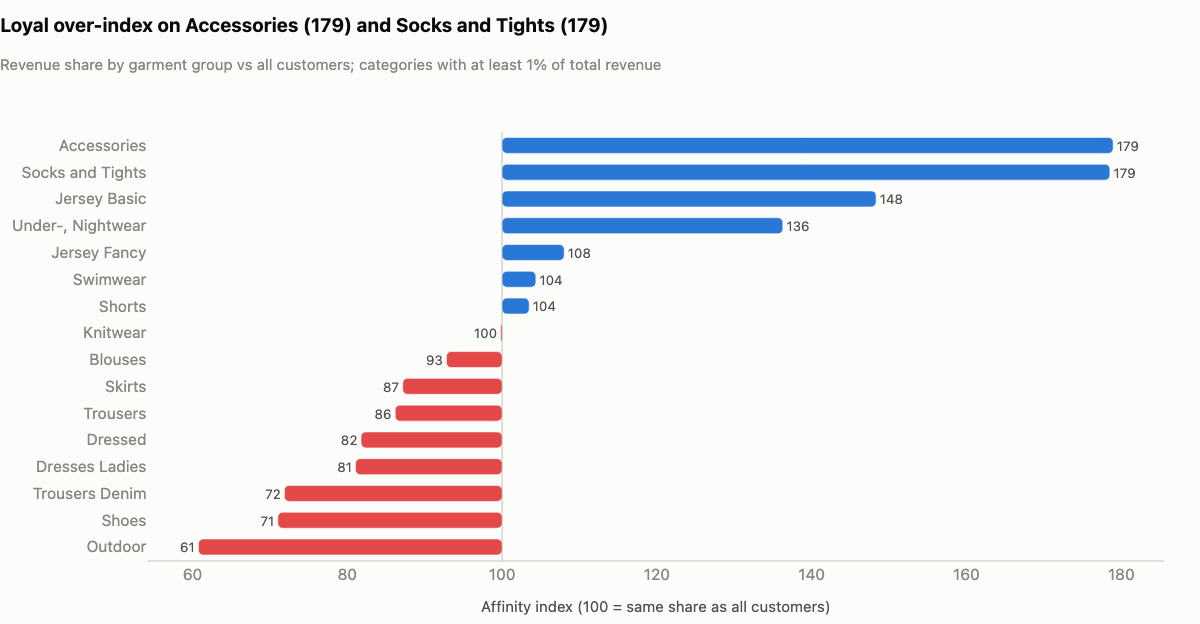

In [14]:
C.category_affinity(mix, "Loyal")

**Takeaway:** Loyal over-index on accessories (179), socks and tights (179) and jersey basics (148): small add-on items that fit their
24 CU baskets, so their arm is about building the basket, not about more visits.

The campaign uses a category only where a segment clearly over-indexes (index ≥ 120 **and** ≥ 5% of the segment's revenue, garment
groups and departments). Champions and Slipping Regulars mirror the overall mix, so their messages are personalised on each
customer's own history instead.

In [15]:
focus = CP.category_focus().reindex(SEGMENT_ORDER).rename_axis("Segment").reset_index()
table(focus.rename(columns={"category_focus": "Category focus used in the campaign (affinity index)"}))

Segment,Category focus used in the campaign (affinity index)
Champions,their own usual categories
Loyal,"Accessories (179), Jersey Basic (148)"
Slipping Regulars,their own usual categories
Potential Loyalists,Sport dept. (126)
New Customers,"Swimwear (141), Sport dept. (124)"
Needs Attention,Swimwear (184)
At Risk,"Knitwear (123), Outdoor (122)"
Hibernating,"Under-, Nightwear (128)"
Lost,"Baby/Children dept. (330), Menswear dept. (125)"
Review List,"Blouses (133), Jersey Basic (126)"


At Risk mixes two recency groups that the plan treats as separate audiences. A look-up on the same 12-month window shows which of them
carries the knitwear and outdoor skew:

In [16]:
split = query("""
    WITH cur AS (
        SELECT customer_id, segment, r_score FROM 'data/marts/customer_rfm.parquet'
        WHERE snapshot_name = 'current' AND segment <> 'Review List'
    ),
    lines AS (
        SELECT CASE WHEN c.segment = 'At Risk' AND c.r_score = 2 THEN 'At Risk, 121-180 days'
                    WHEN c.segment = 'At Risk' THEN 'At Risk, 181-364 days' ELSE 'everyone else' END AS grp,
               a.garment_group_name AS garment_group, l.line_revenue_cents AS revenue
        FROM 'data/marts/fct_sales_lines.parquet' l
        JOIN cur c USING (customer_id)
        JOIN 'data/staged/stg_articles.parquet' a USING (article_id)
        WHERE DATE '2020-09-22' - l.order_date < 365
    ),
    g AS (SELECT grp, garment_group, SUM(revenue) AS revenue FROM lines GROUP BY ALL),
    s AS (SELECT grp, garment_group, revenue / SUM(revenue) OVER (PARTITION BY grp) AS share FROM g),
    o AS (SELECT garment_group, SUM(revenue) / (SELECT SUM(revenue) FROM g) AS overall FROM g GROUP BY 1)
    SELECT s.grp, s.garment_group, 100 * s.share / o.overall AS affinity_index
    FROM s JOIN o USING (garment_group)
    WHERE s.grp <> 'everyone else'
""")
last_order = query("""
    SELECT CASE WHEN r_score = 2 THEN 'At Risk, 121-180 days' ELSE 'At Risk, 181-364 days' END AS grp,
           COUNT(*) AS customers, strftime(MIN(last_order_date), '%Y-%m-%d') AS first_last_order,
           strftime(MAX(last_order_date), '%Y-%m-%d') AS latest_last_order
    FROM 'data/marts/customer_rfm.parquet'
    WHERE snapshot_name = 'current' AND segment = 'At Risk'
    GROUP BY ALL ORDER BY 1
""").set_index("grp")
piv = split.pivot(index="grp", columns="garment_group", values="affinity_index")
cols = ["Knitwear", "Outdoor", "Trousers", "Swimwear", "Shorts"]
out = last_order.join(piv[cols]).reset_index().rename(columns={"grp": "Audience", "customers": "Customers",
                                                             "first_last_order": "Last order from", "latest_last_order": "Last order to"})
table(out, {"Customers": "{:,.0f}", **{c: "{:.0f}" for c in cols}})

Audience,Customers,Last order from,Last order to,Knitwear,Outdoor,Trousers,Swimwear,Shorts
"At Risk, 121-180 days","42,394",2020-03-26,2020-05-24,91,94,110,112,117
"At Risk, 181-364 days","47,454",2019-09-24,2020-03-25,157,154,104,46,29


**Takeaway:** The knitwear and outdoor skew belongs to the 181-364-day group (index 157 and 154; last order September 2019 to March
2020). The 121-180-day group last bought in late March to May 2020, mostly while stores were closed, and under-indexes on both
(91 and 94), so its win-back email should lead with each customer's own top categories rather than knitwear.

### 5. Who only buys online, and does it matter?

**The audience.** 482,607 of the customers active in the last 12 months (49%) had no identified store purchase in that time;
147,213 of them are reachable by email and 55,909 are Champions, Loyal or Slipping Regulars. 187,556 active customers are the mirror
image: store only. Where the online-only customers sit:

In [17]:
aud = D.mart("channel_audience")
oo = aud[(aud.channel == "Online only") & ~aud.segment.isin(["Lost", "Review List"])].copy()
oo = oo.assign(share=oo.customers / oo.customers.sum(), reach=oo.newsletter_subscribers / oo.customers)
oo = D.ordered(oo).sort_values("customers", ascending=False)
table(oo[["segment", "customers", "share", "newsletter_subscribers", "reach", "revenue_12m_cu"]].rename(columns={
          "segment": "Segment", "customers": "Online-only customers", "share": "% of online-only",
          "newsletter_subscribers": "Reachable by email", "reach": "% email reach", "revenue_12m_cu": "12-month revenue (CU)"}),
      {"Online-only customers": "{:,.0f}", "% of online-only": "{:.0%}", "Reachable by email": "{:,.0f}",
       "% email reach": "{:.0%}", "12-month revenue (CU)": "{:,.0f}"})

Segment,Online-only customers,% of online-only,Reachable by email,% email reach,12-month revenue (CU)
Hibernating,"202,686",42%,"51,214",25%,"12,051,020"
Needs Attention,"75,758",16%,"25,345",33%,"10,238,192"
Potential Loyalists,"55,017",11%,"18,856",34%,"9,767,573"
New Customers,"47,105",10%,"13,292",28%,"3,216,151"
At Risk,"46,132",10%,"13,998",30%,"13,543,621"
Champions,"37,707",8%,"16,730",44%,"30,069,803"
Slipping Regulars,"14,287",3%,"5,967",42%,"7,296,599"
Loyal,"3,915",1%,"1,811",46%,"608,283"


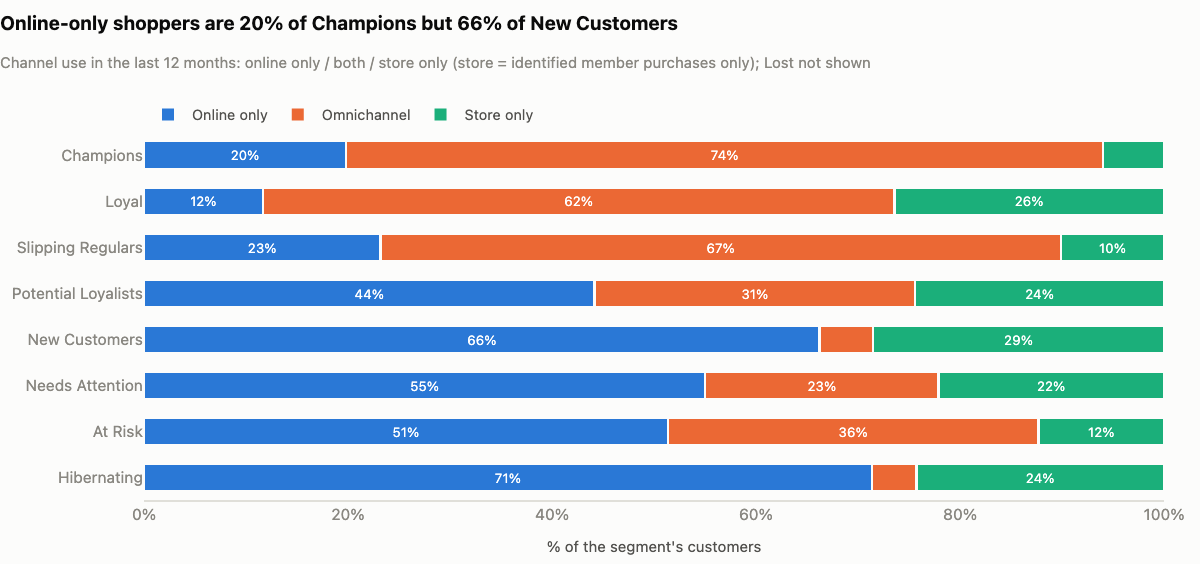

In [18]:
C.channel_mix(mix)

**Takeaway:** Online only is 20% of Champions but 66% of New Customers and 71% of Hibernating: the channel mix follows the lifecycle,
and 42% of all online-only customers are Hibernating.

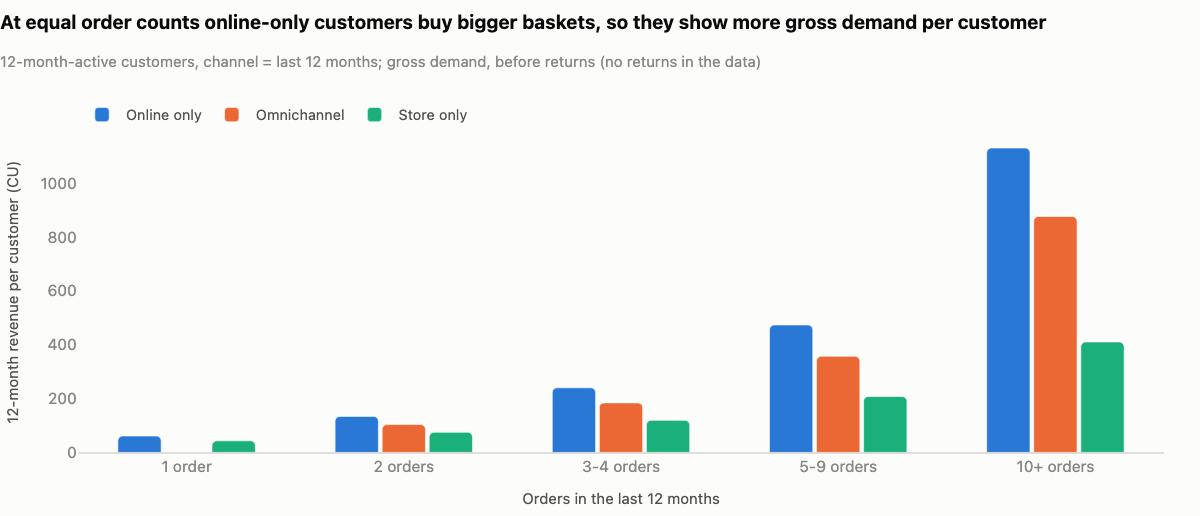

In [19]:
cv = D.mart("channel_value")
C.channel_value(cv)

**Takeaway:** At equal order counts online-only customers show more gross demand: 474 CU in 12 months at 5-9 orders against 357 CU
for omnichannel customers.

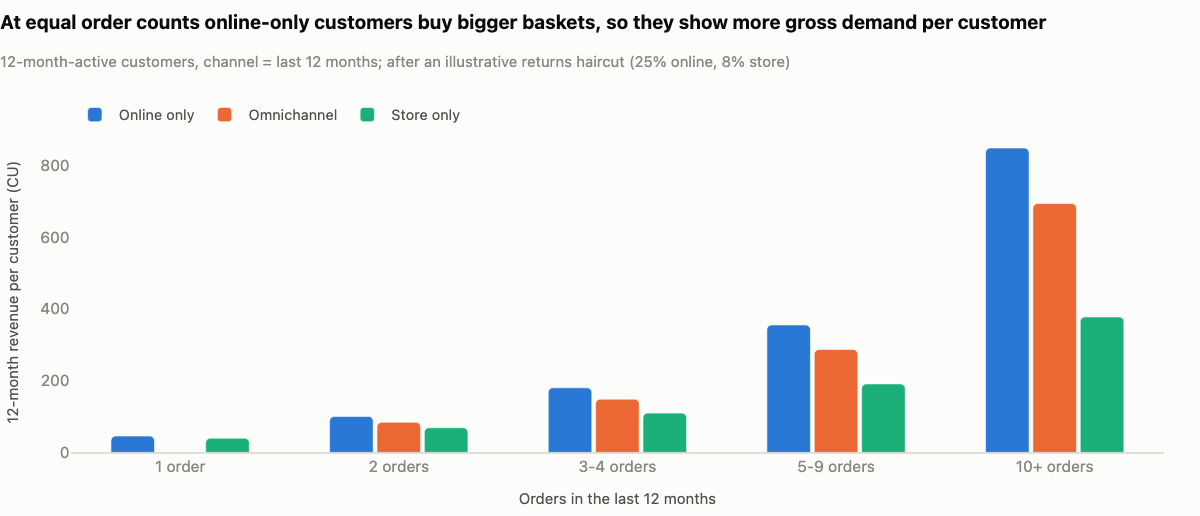

In [20]:
C.channel_value(cv, net_of_returns=True)

**Takeaway:** With an illustrative returns haircut (25% online, 8% store; an assumption, not a measured rate) the 5-9-order gap
shrinks from 116 to 69 CU, so the comparison depends on returns the data cannot show.

In [21]:
aov = D.mart("channel_order_aov")
table(aov.rename(columns={"customers_group": "Customers", "order_channel": "Order channel", "orders": "Orders (12m)",
                          "aov_cu": "AOV (CU)", "units_per_order": "Items per order"}),
      {"Orders (12m)": "{:,.0f}", "AOV (CU)": "{:.1f}", "Items per order": "{:.1f}"})

Customers,Order channel,Orders (12m),AOV (CU),Items per order
All customers,Online,"2,729,595",69.4,3.9
All customers,Store,"1,659,459",34.0,2.5
Omnichannel customers,Online,"1,475,782",69.6,3.9
Omnichannel customers,Store,"1,165,996",33.4,2.5


**Takeaway:** For the same omnichannel customers an online order is 69.6 CU and 3.9 items against 33.4 CU and 2.5 items in store,
about twice the basket, so "online-only customers spend more" is mostly basket size, not a different kind of customer.

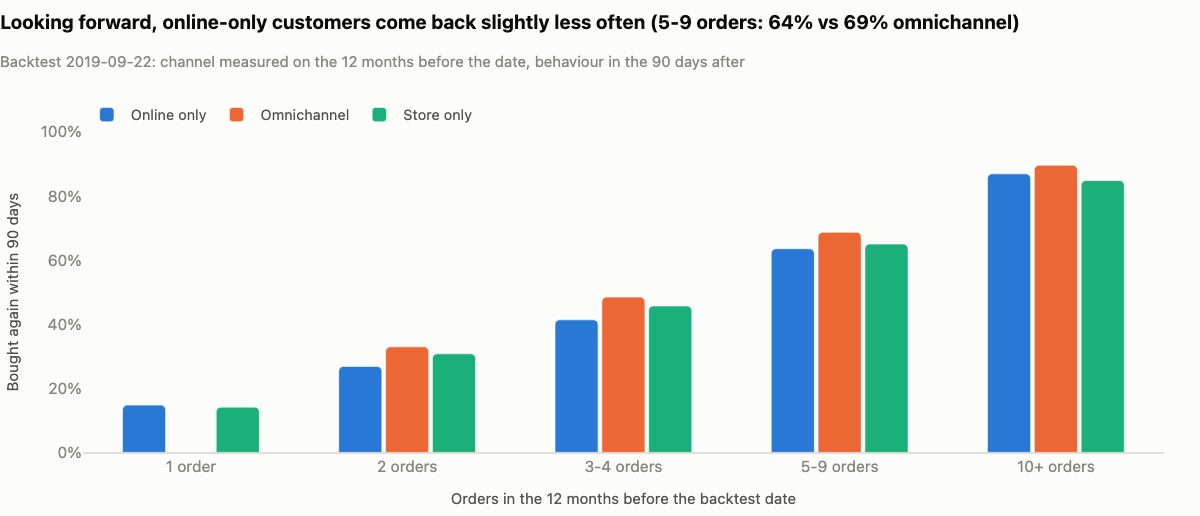

In [22]:
C.channel_forward(D.mart("channel_forward"))

**Takeaway:** Looking forward from 2019-09-22, online-only customers came back slightly less often than omnichannel customers in
every band from 2 orders up (5-9 orders: 64% vs 69%; store only 65%).

**What it means for the campaign.** These are comparisons between groups of customers, not experiments. They show that online-only
customers are not worth less per order, and nothing in them shows that getting online-only customers into a store would make them
more valuable, so the plan does not pay for a store push. Channel decides the **message** in every arm:

| Channel in the last 12 months | Treatment rule in every arm |
|---|---|
| Online only | online creative, delivery and free-returns message, app; excluded from store events |
| Store only | store-led creative (new in store, click-and-collect, in-store returns); no online-only vouchers |
| Omnichannel | both; click-and-collect as the bridge |

A store-visit incentive for online-only customers can be tested later as its own holdout arm if Retail asks for it.

### 6. If we do nothing: the next 90 days

Grey = what a segment would spend in 90 days at its usual 12-month pace; blue = what look-alike customers actually spent after
2019-09-22, re-weighted to today's mix; labels = the gap vs usual pace. "Do nothing" means business as usual: the backtest period
already contains the normal newsletters and sales.

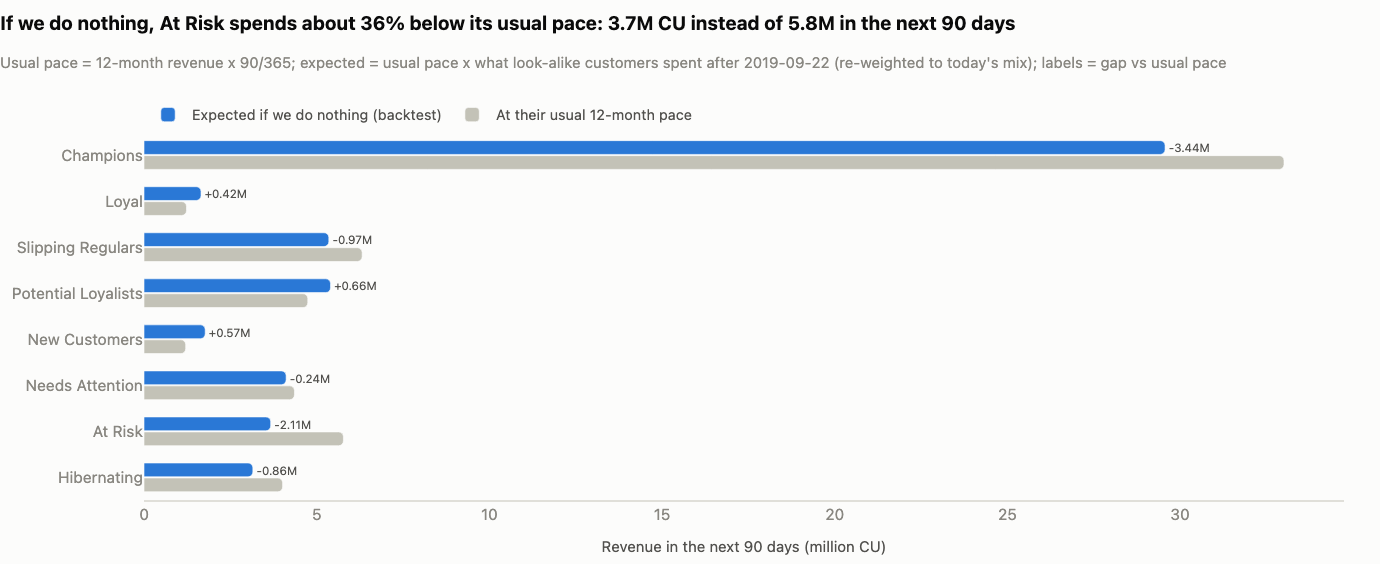

In [23]:
rar = D.mart("revenue_at_risk")
C.run_rate_vs_expected(rar).show(width=1150)  # wider than the default so the long subtitle is not cut off

**Takeaway:** Left alone, At Risk is expected to spend 3.7M CU in the next 90 days instead of 5.8M CU at its usual pace (36% below),
Slipping Regulars 5.4M instead of 6.3M CU, and Champions 29.6M instead of 33.0M CU.

In [24]:
r = D.ordered(rar)
table(pd.DataFrame({
    "Segment": r.segment, "Customers": r.customers, "Usual 90-day pace (CU)": r.run_rate_90d_cu,
    "Expected, do nothing (CU)": r.expected_90d_cu_base, "Gap vs pace (CU)": r.gap_90d_cu_base,
    "Gap, low scenario (CU)": r.gap_90d_cu_low, "Gap, high scenario (CU)": r.gap_90d_cu_high,
    "Plan's expected incremental revenue (CU)": r.addressable_90d_cu,
    "Buy again within 90 days": r.repurchase_rate_base, "Expected non-buyers": r.expected_non_buyers_base,
    "Reference date": r.base_basis.map({"seasonal": "2019-09-22", "recent": "2020-06-24"}),
}), {c: "{:,.0f}" for c in ["Customers", "Usual 90-day pace (CU)", "Expected, do nothing (CU)", "Gap vs pace (CU)",
                            "Gap, low scenario (CU)", "Gap, high scenario (CU)", "Plan's expected incremental revenue (CU)",
                            "Expected non-buyers"]} | {"Buy again within 90 days": "{:.1%}"})

Segment,Customers,Usual 90-day pace (CU),"Expected, do nothing (CU)",Gap vs pace (CU),"Gap, low scenario (CU)","Gap, high scenario (CU)",Plan's expected incremental revenue (CU),Buy again within 90 days,Expected non-buyers,Reference date
Champions,"190,320","33,012,083","29,568,076","3,444,007","3,444,007","4,666,940","23,691",82.6%,"33,208",2019-09-22
Loyal,"33,612","1,230,498","1,651,398","-420,899","-420,899","-375,998","1,742",68.3%,"10,670",2019-09-22
Slipping Regulars,"61,655","6,317,226","5,352,057","965,169","965,169","1,526,271","20,320",67.1%,"20,310",2019-09-22
Potential Loyalists,"124,517","4,742,893","5,401,602","-658,709","-658,709","-181,544","24,478",48.1%,"64,586",2019-09-22
New Customers,"71,117","1,207,149","1,772,459","-565,310","-565,310","-243,654","74,308",28.4%,"50,936",2019-09-22
Needs Attention,"137,675","4,356,753","4,115,999","240,755","240,755","534,276","25,910",33.2%,"91,982",2019-09-22
At Risk,"89,848","5,774,253","3,668,360","2,105,894","2,105,894","2,408,597","44,510",34.7%,"58,643",2019-09-22
Hibernating,"284,069","4,013,479","3,151,966","861,514","413,492","938,763","10,243",14.0%,"244,267",2019-09-22
Lost,"368,604",0,"1,805,322",-,-,-,"10,578",6.3%,"345,322",2020-06-24
Review List,864,"315,132","323,895","-8,763","-15,904","-6,566",0,66.1%,293,2020-06-24


**The gap vs usual pace is not money a campaign can recover.** Customers are put in a segment *because* of their last 12 months, so
part of every gap is natural slowdown. Read it next to the plan's expected incremental revenue: for At Risk about 45K CU against a
2.1M CU gap (2%; 26K of the 45K from content emails, the rest from the 10% offer test cell, which is expected to lose money on its own). Negative gaps (Loyal, Potential Loyalists, New Customers) are customers whose 12-month history is short or still
building; Lost has no usual pace, only expected reactivation revenue.

How sure are we about At Risk? Three scenarios, plus the sampling noise of the base case:

In [25]:
ar = rar.set_index("segment").loc["At Risk"]
noise = ar.run_rate_90d_cu * (ar.realisation_ci_hi_seasonal - ar.realisation_ci_lo_seasonal) / 2
scen_ar = pd.DataFrame([
    ("Base: same season last year (2019-09-22), re-weighted", ar.realisation_seasonal, ar.expected_90d_cu_seasonal, ar.gap_90d_cu_seasonal),
    ("Last quarter (2020-06-24, the reopening summer), re-weighted", ar.realisation_recent, ar.expected_90d_cu_recent, ar.gap_90d_cu_recent),
    ("Pessimistic: the worse of the two in every cell", ar.realisation_pessimistic, ar.expected_90d_cu_pessimistic, ar.gap_90d_cu_pessimistic),
], columns=["Scenario", "Share of usual pace", "Expected next 90 days (CU)", "Gap vs pace (CU)"])
print(f"Sampling noise on the base gap (delta method, 95%): +/- {noise:,.0f} CU")
table(scen_ar, {"Share of usual pace": "{:.1%}", "Expected next 90 days (CU)": "{:,.0f}", "Gap vs pace (CU)": "{:,.0f}"})

Sampling noise on the base gap (delta method, 95%): +/- 54,931 CU


Scenario,Share of usual pace,Expected next 90 days (CU),Gap vs pace (CU)
"Base: same season last year (2019-09-22), re-weighted",63.5%,"3,668,360","2,105,894"
"Last quarter (2020-06-24, the reopening summer), re-weighted",62.8%,"3,627,199","2,147,054"
Pessimistic: the worse of the two in every cell,58.3%,"3,365,656","2,408,597"


**Takeaway:** The scenario range (2.1M-2.4M CU) is the uncertainty to quote; sampling noise is only about ±55K CU and says nothing
about whether autumn 2020 behaves like autumn 2019.

Why do Champions show a 3.4M CU gap? Realisation (actual 90-day spend / usual pace) by M score inside each segment, 2019 backtest:

In [26]:
rtm = D.mart("regression_to_mean")
keep = ["Champions", "Slipping Regulars", "Potential Loyalists", "Needs Attention", "At Risk", "Hibernating"]
piv = rtm[rtm.segment.isin(keep)].pivot(index="segment", columns="m_score", values="realisation").reindex(keep)
piv.columns = [f"M{c}" for c in piv.columns]
table(piv.reset_index().rename(columns={"segment": "Segment"}), {c: "{:.0%}" for c in piv.columns})

Segment,M1,M2,M3,M4,M5
Champions,-,-,-,105%,86%
Slipping Regulars,210%,145%,109%,89%,79%
Potential Loyalists,265%,170%,120%,92%,75%
Needs Attention,179%,124%,93%,78%,68%
At Risk,151%,105%,78%,60%,57%
Hibernating,119%,67%,52%,-,-


**Takeaway:** Inside every segment the top spenders fall back and the lower spenders catch up: Champions spending 400+ CU realised 86%
of their usual pace and those spending 200-399 CU 105%, so Champions' gap is regression to the mean after a strong year, not churn.

One more reason for caution about At Risk: when did today's At Risk customers last buy?

In [27]:
lock = query("""
    SELECT strftime(last_order_date, '%Y-%m') AS last_order_month,
           COUNT(*) AS customers,
           COUNT(*) / SUM(COUNT(*)) OVER () AS share
    FROM 'data/marts/customer_rfm.parquet'
    WHERE snapshot_name = 'current' AND segment = 'At Risk'
    GROUP BY ALL ORDER BY 1
""")
by_band = query("""
    SELECT CASE WHEN r_score = 2 THEN '121-180 days' ELSE '181-364 days' END AS recency,
           AVG((last_order_date BETWEEN DATE '2020-03-01' AND DATE '2020-05-31')::INT) AS share_last_bought_mar_may_2020
    FROM 'data/marts/customer_rfm.parquet'
    WHERE snapshot_name = 'current' AND segment = 'At Risk'
    GROUP BY ALL ORDER BY 1
""")
print(f"Share of At Risk whose last order was in March-May 2020: {H['at_risk_lockdown_share']:.1%}")
display(table(by_band.rename(columns={"recency": "At Risk, days since last order",
                                      "share_last_bought_mar_may_2020": "Last order in March-May 2020"}),
              {"Last order in March-May 2020": "{:.0%}"}))
table(lock.rename(columns={"last_order_month": "Month of last order", "customers": "At Risk customers", "share": "% of At Risk"}),
      {"At Risk customers": "{:,.0f}", "% of At Risk": "{:.1%}"})

Share of At Risk whose last order was in March-May 2020: 59.8%


"At Risk, days since last order",Last order in March-May 2020
121-180 days,100%
181-364 days,24%


Month of last order,At Risk customers,% of At Risk
2019-09,442,0.5%
2019-10,"2,435",2.7%
2019-11,"4,645",5.2%
2019-12,"7,158",8.0%
2020-01,"9,066",10.1%
2020-02,"12,382",13.8%
2020-03,"13,929",15.5%
2020-04,"20,387",22.7%
2020-05,"19,404",21.6%


**Takeaway:** 60% of today's At Risk customers last bought in March-May 2020 (all of the 121-180-day group and 24% of the
181-364-day group), a situation neither backtest year contains; this is why the realisation is re-weighted cell by cell and why the
pessimistic scenario is shown.

### 7. Segments move fast: one quarter of migration

Each row is a segment on 2020-06-24; the cells show where those customers were on 2020-09-22. The diagonal is "stayed".

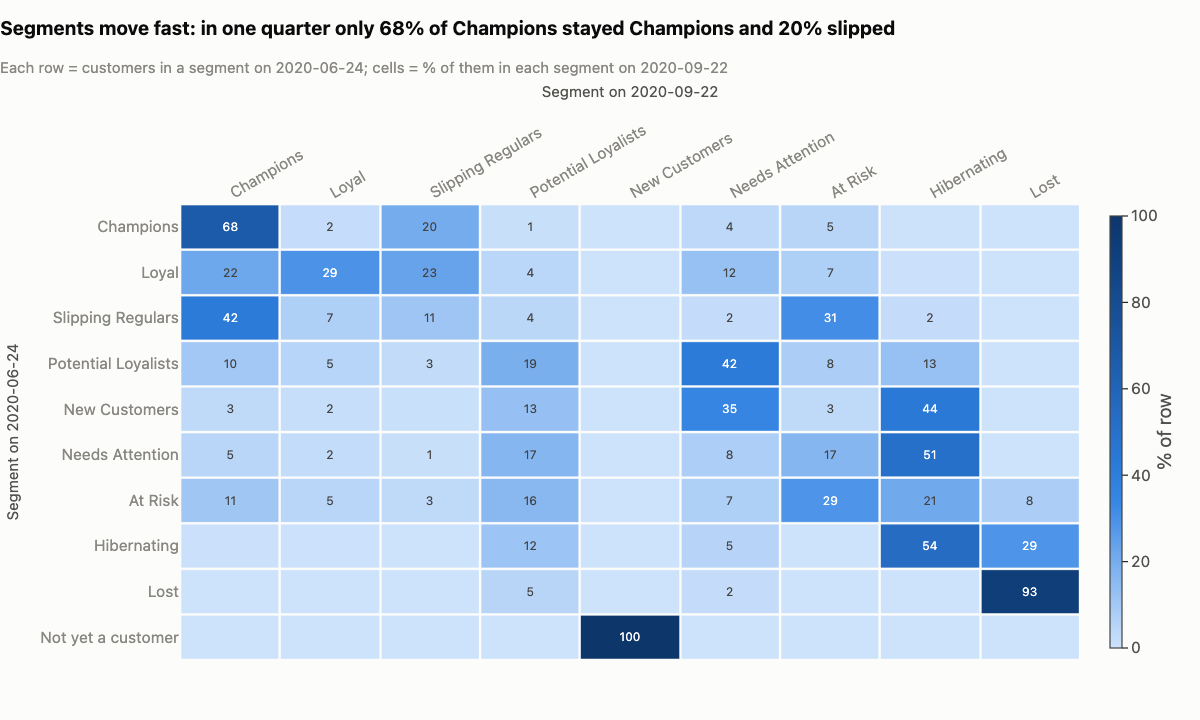

In [28]:
flow = D.mart("segment_flow")
C.segment_flow(flow)

**Takeaway:** 51% of customers changed segment in one quarter: only 68% of June's Champions were still Champions in September (20%
had slipped to Slipping Regulars), and 8% of June's At Risk had become Lost before anyone contacted them, so audiences are re-scored
on launch day, not taken from this extract.

### 8. The autumn plan and what it is expected to return

One row per audience and arm. *Rollout* = the recommended action; *Test cell* = a smaller group where a discount is tried, to learn
whether it pays before anyone rolls it out; *Not run* = considered and rejected, kept so the reasoning stays visible. The Review List gets
no offers or paid media until it is reviewed. Launch in the week of 2020-09-28.

In [29]:
plan = CP.plan_frame()
plan_view = pd.DataFrame({
    "Audience": plan.audience_label, "Arm": plan.arm, "Role": plan.role, "Action": plan.action, "Timing": plan.timing,
    "Channel": plan.channels, "Discount": plan.discount_rate.map(lambda v: "none" if v == 0 else f"{v:.0%} off one order"),
    "Assumed lift (pp, ITT)": plan.uplift_pp,
})
no_spend = pd.DataFrame([{"Audience": k, "Arm": "No autumn campaign", "Role": "-", "Action": v} for k, v in CP.NO_CAMPAIGN.items()])
table(pd.concat([plan_view, no_spend], ignore_index=True), {"Assumed lift (pp, ITT)": "{:+.1f}"})

Audience,Arm,Role,Action,Timing,Channel,Discount,"Assumed lift (pp, ITT)"
Champions,Autumn early access,Rollout,Personal 48-hour early-access link to the autumn collection; free click-and-collect on the early-access order. No % discount.,"2020-09-29, two days before the public launch",Email + personalised member-app message (subscribers only),none,+0.5
Loyal,Basket-building picks,Rollout,"'Complete your order' picks (accessories, basics multipacks) and a free-delivery threshold reminder. No discount.",Week 2 (from 2020-10-05),Email + member-app message (subscribers only),none,+0.5
Loyal,Picks + 10% voucher,Not run,Same picks + voucher worth 10% of the next order,-,Email,10% off one order,+1.5
Slipping Regulars,Purchase-cycle reminder: autumn picks,Rollout,"'New in for autumn' picks from the categories they bought most, sent in week 1; second touch on day 10 to those who have not bought since launch. No discount.","Week 1 (2020-09-28), reminder day 10",Email + member-app message (subscribers only),none,+1.5
Potential Loyalists,Complete-the-look recommendations,Rollout,Personalised 'complete the look' email from the last order's category; customers who came back after 12+ months get a 'welcome back' version. No discount.,Week 1 (from 2020-09-28),Email + member-app message (subscribers only),none,+1.0
New Customers,Welcome journey,Rollout,"3-email journey over 30 days (membership benefits, picks from the first order's category, delivery / returns / click-and-collect explained). No discount.",Starts day 7 after the first order; customers already in the segment enter in week 1,Email (subscribers) + paid social for the two thirds not reachable by email,none,+1.5
New Customers,Welcome journey + 10% off 2nd order,Test cell,"Same journey + 10% off the second order, valid 30 days",Same as the journey (parallel cell),Email (subscribers) + paid social,10% off one order,+3.0
Needs Attention,Summer-to-autumn new-arrivals edit,Rollout,"New-arrivals edit that bridges from what they bought in summer (swimwear, underwear) to autumn basics; one-order customers get the second-order version of the welcome email. No discount.",Week 1 (from 2020-09-28); reminder in week 3 to those who have not bought,Email + member-app message (subscribers only),none,+1.0
"At Risk, 121-180 days",Win-back content (email only),Rollout,Personalised 'we picked these for you' email from each customer's own top categories (this group last bought during the spring 2020 store closure and has no seasonal skew). No discount.,Week 1 (from 2020-09-28); reminder on day 7 to those who have not bought,Email (subscribers only),none,+1.0
"At Risk, 181-364 days, 200+ CU",Win-back content + paid social,Rollout,Personalised win-back leading with outerwear and knitwear (they last bought in autumn / winter 2019-20 and over-index on both); paid-social retargeting to non-subscribers with the same creative. No discount.,"Week 1 (from 2020-09-28); retargeting runs 3 weeks, stops for anyone who buys","Email (subscribers) + paid social (non-subscribers, holdout uploaded as an exclusion audience)",none,+1.0


In [30]:
econ = D.mart("campaign_economics")
table(pd.DataFrame({
    "Audience": econ.audience_label, "Arm": econ.arm, "Role": econ.role, "Contacted": econ.contacted,
    "Buy anyway (BAU)": econ.baseline_rate, "Assumed lift (pp)": econ.uplift_pp, "Break-even lift (pp)": econ.breakeven_uplift_pp,
    "Incremental revenue (CU)": econ.incremental_revenue_cu, "Discount cost (CU)": econ.discount_cost_cu,
    "Contact cost (CU)": econ.contact_cost_cu, "Net profit (CU)": econ.net_profit_cu,
}), {"Contacted": "{:,.0f}", "Buy anyway (BAU)": "{:.1%}", "Assumed lift (pp)": "{:.1f}", "Break-even lift (pp)": "{:.2f}",
     "Incremental revenue (CU)": "{:,.0f}", "Discount cost (CU)": "{:,.0f}", "Contact cost (CU)": "{:,.0f}",
     "Net profit (CU)": "{:,.0f}"})

Audience,Arm,Role,Contacted,Buy anyway (BAU),Assumed lift (pp),Break-even lift (pp),Incremental revenue (CU),Discount cost (CU),Contact cost (CU),Net profit (CU)
Champions,Autumn early access,Rollout,"80,774",83.2%,0.5,0.04,"23,691",0,808,"8,669"
Loyal,Basket-building picks,Rollout,"14,613",68.3%,0.5,0.10,"1,742",0,146,551
Loyal,Picks + 10% voucher,Not run,0,68.3%,1.5,11.53,0,0,0,0
Slipping Regulars,Purchase-cycle reminder: autumn picks,Rollout,"24,602",68.0%,1.5,0.05,"20,320",0,246,"7,882"
Potential Loyalists,Complete-the-look recommendations,Rollout,"43,130",48.9%,1.0,0.04,"24,478",0,431,"9,360"
New Customers,Welcome journey,Rollout,"32,003",28.5%,1.5,0.99,"24,769",0,"6,536","3,371"
New Customers,Welcome journey + 10% off 2nd order,Test cell,"32,003",28.5%,3.0,6.07,"49,539","28,487","6,536","-15,208"
Needs Attention,Summer-to-autumn new-arrivals edit,Rollout,"45,741",34.8%,1.0,0.04,"25,910",0,457,"9,907"
"At Risk, 121-180 days",Win-back content (email only),Rollout,"13,092",43.9%,1.0,0.04,"9,317",0,131,"3,596"
"At Risk, 181-364 days, 200+ CU",Win-back content + paid social,Rollout,"14,376",26.5%,1.0,0.50,"15,048",0,"3,017","3,002"


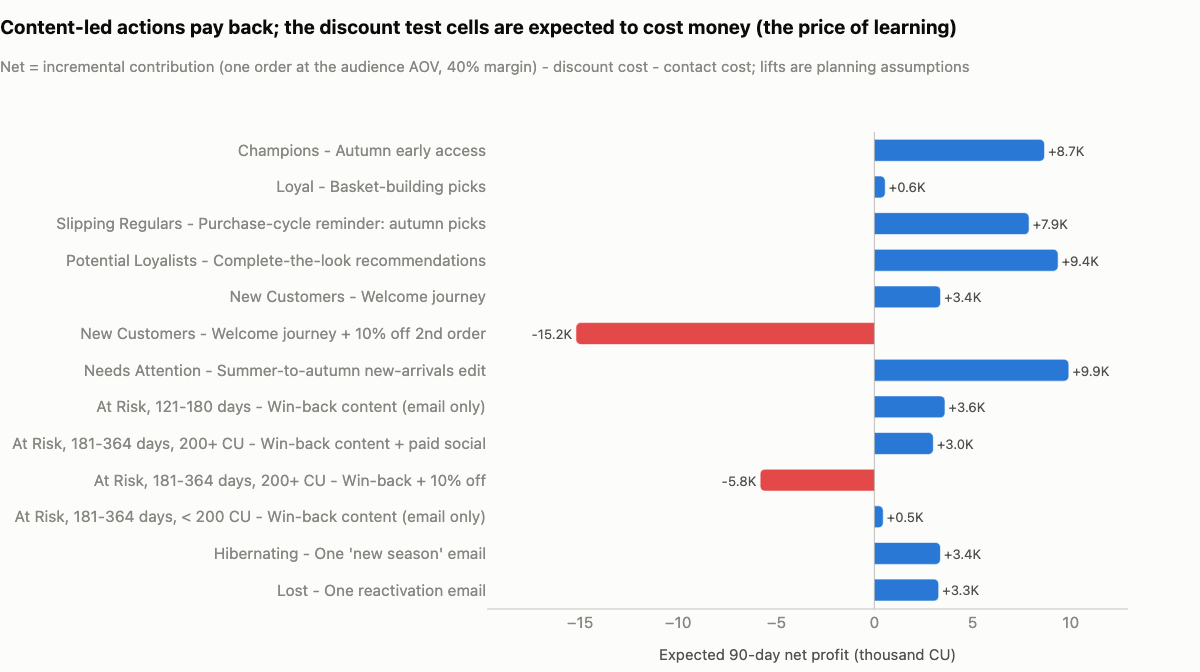

In [31]:
C.net_profit_by_arm(econ)

**Takeaway:** Content arms pay back because they cost almost nothing (the rollout costs 13.5K CU against an expected 167K CU of
incremental revenue under the planning assumptions), while the two coupon cells are expected to lose 15.2K and 5.8K CU, the price of
finding out whether a discount pays.

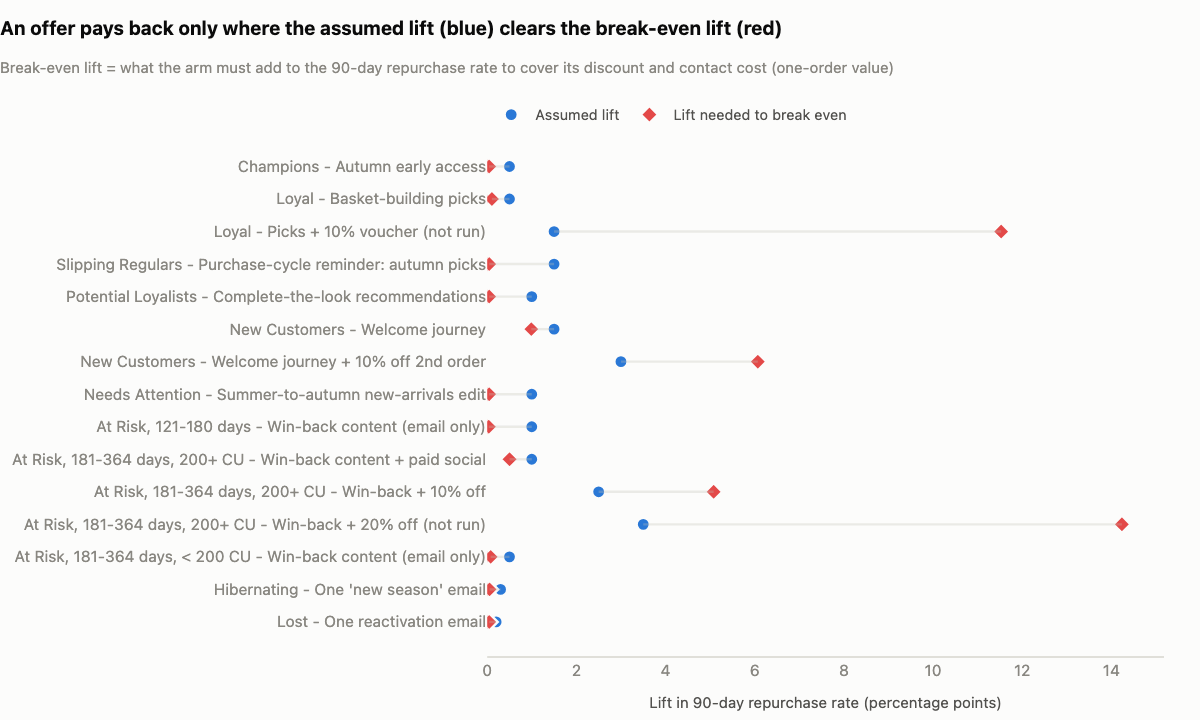

In [32]:
C.breakeven_vs_assumed(econ)

**Takeaway:** A 10% coupon needs a lift of 5-6 points just to break even (6.07 pp on the New Customers' second order, 5.08 pp in
At Risk; the 20% offer would need 14.2 pp and the Loyal voucher 11.5 pp, which is why neither runs), because the discount is also paid
on orders from customers who would have bought anyway.

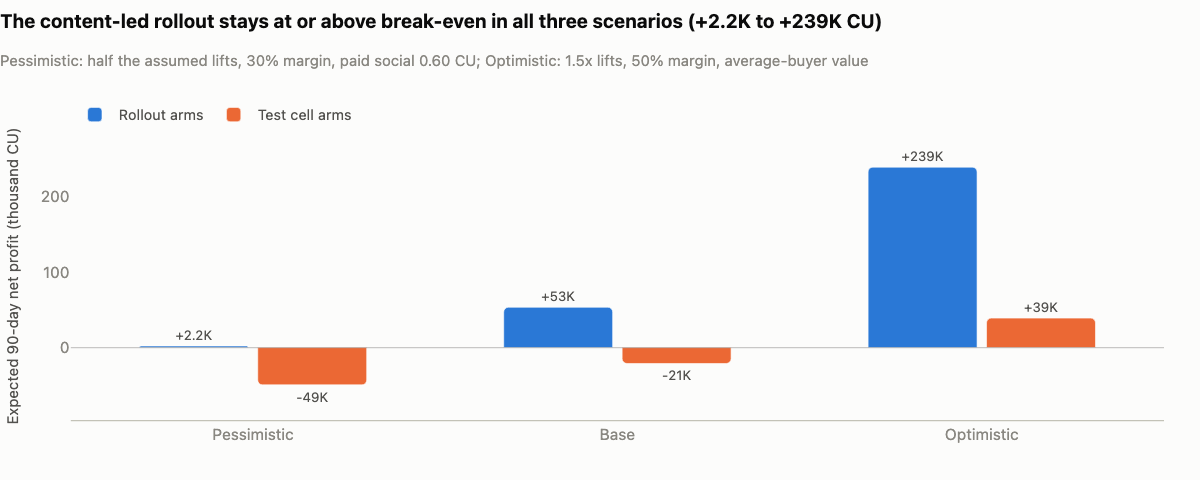

In [33]:
scen = D.mart("campaign_scenarios")
C.scenario_bars(scen)

**Takeaway:** The content-led rollout stays at or above break-even in all three scenarios (+2.2K to +239K CU), even at half the
assumed lifts, while the test cells only pay in the optimistic case (-49K to +39K CU), which is exactly the question the test cells are
there to settle.

In [34]:
budget = D.mart("campaign_budget")
table(budget.rename(columns={"line": "Line", "cost_cu": "CU", "note": "How it is calculated"}), {"CU": "{:,.0f}"})

Line,CU,How it is calculated
Email sends (all rollout arms),"4,141","414,129 contacts x 0.01 CU"
"Paid social (New Customers journey, At Risk 181-364 days 200+ CU)","9,403","31,344 non-subscribers x 0.3 CU"
Test cells: discounts,"40,325",coupon value on all redeemed orders in the two test cells
Test cells: contacts,"8,045",email + paid social for the test cells
Total budget ask,"61,915",cash cost of the autumn wave
Memo: profit given up by holding out 10%,"6,478",holdout x assumed lift x one-order value x margin (the price of being able to measure)
Memo: expected net of test cells,"-21,031",negative = what we expect to pay to learn whether the offers work


**Takeaway:** The budget ask is 61.9K CU (4.1K email and 9.4K paid social for the rollout, 40.3K coupon value and 8.0K contacts in the
test cells), and holding out 10% gives up about 6.5K CU of expected profit, the price of being able to measure. If the budget is cut,
drop in this order: the At Risk 10% test cell, paid social for the New Customers journey, then the New Customers coupon cell; the
content arms and email are never cut.

### 9. How we will measure it

- **Control group.** In every audience 10% of the reachable customers are held out by a salted hash of the customer id, stratified by
  audience and balance-checked at launch (12-month spend, subscriber share). The holdout gets **no campaign communication** (no
  campaign emails, app messages or early-access links; excluded from paid-social audiences and lookalike seeds) but keeps the
  business-as-usual newsletters, including Black Friday and Christmas. We measure the campaign on top of business as usual.
- **Estimand.** Intention-to-treat: everyone assigned to an arm counts, opened or not, matched in paid social or not. The assumed
  lifts above are ITT lifts per assigned customer.
- **KPIs.** Primary for every arm: the **90-day repurchase rate**. Secondary: revenue per customer and net profit after discount and
  contact cost.
- **Reads.** The pooled campaign-wide read is the main read. The two coupon cells are sized so their detectable lift is at most two
  thirds of their break-even. Single content arms are directional. The day-30 read covers delivery and guardrails only
  (unsubscribes, complaints). Comparisons within At Risk are Holm-adjusted.
- **Decision rule.** Scale an offer only if the 95% lower bound of its lift over the content cell clears its break-even.

In [35]:
pooled = pd.Series(CAMP["pooled_read"])
pd.DataFrame({"Pooled read (all live arms)": [
    f"{pooled.population:,}", f"{pooled.holdout_customers:,}", f"{pooled.baseline_rate:.1%}",
    f"{pooled.mde_rate_pp:.2f} pp", f"{pooled.expected_lift_pp:.2f} pp", "yes" if pooled.detectable else "no"]},
    index=["Reachable population", "Holdout customers", "Business-as-usual repurchase rate (weighted)",
           "Minimum detectable lift", "Expected lift if every arm hits its assumption", "Detectable?"])

,Pooled read (all live arms)
Reachable population,"538,515"
Holdout customers,"53,852"
Business-as-usual repurchase rate (weighted),37.1%
Minimum detectable lift,0.51 pp
Expected lift if every arm hits its assumption,0.84 pp
Detectable?,yes


**Takeaway:** The pooled holdout of 53.9K customers detects a campaign-wide lift of 0.51 pp, against 0.84 pp expected if every arm
delivers its assumption, so a campaign-wide lift of 0.51 pp or more shows up in the 2020-12-27 read with 80% power.

In [36]:
live = econ[econ.role != "Not run"]
table(pd.DataFrame({
    "Audience": live.audience_label, "Arm": live.arm, "Role": live.role, "Reachable population": live.experiment_population,
    "Holdout": live.holdout, "Arm size": live.contacted, "Assumed lift (pp)": live.uplift_pp,
    "Break-even (pp)": live.breakeven_uplift_pp, "Detectable lift (pp)": live.mde_rate_pp,
    "Readable alone": live.readable_alone.map({True: "yes", False: "no: pooled read"}),
    "Sized for its decision": np.where(live.role == "Test cell", live.powered_for_decision.map({True: "yes", False: "no"}), "-"),
}), {"Reachable population": "{:,.0f}", "Holdout": "{:,.0f}", "Arm size": "{:,.0f}", "Assumed lift (pp)": "{:.1f}",
     "Break-even (pp)": "{:.2f}", "Detectable lift (pp)": "{:.2f}"})

Audience,Arm,Role,Reachable population,Holdout,Arm size,Assumed lift (pp),Break-even (pp),Detectable lift (pp),Readable alone,Sized for its decision
Champions,Autumn early access,Rollout,"89,749","8,975","80,774",0.5,0.04,1.17,no: pooled read,-
Loyal,Basket-building picks,Rollout,"16,237","1,624","14,613",0.5,0.10,3.41,no: pooled read,-
Slipping Regulars,Purchase-cycle reminder: autumn picks,Rollout,"27,335","2,734","24,602",1.5,0.05,2.63,no: pooled read,-
Potential Loyalists,Complete-the-look recommendations,Rollout,"47,922","4,792","43,130",1.0,0.04,2.13,no: pooled read,-
New Customers,Welcome journey,Rollout,"71,117","7,112","32,003",1.5,0.99,1.66,no: pooled read,-
New Customers,Welcome journey + 10% off 2nd order,Test cell,"71,117","7,112","32,003",3.0,6.07,1.66,yes,yes
Needs Attention,Summer-to-autumn new-arrivals edit,Rollout,"50,823","5,082","45,741",1.0,0.04,1.97,no: pooled read,-
"At Risk, 121-180 days",Win-back content (email only),Rollout,"14,547","1,455","13,092",1.0,0.04,3.84,no: pooled read,-
"At Risk, 181-364 days, 200+ CU",Win-back content + paid social,Rollout,"23,960","2,396","14,376",1.0,0.50,2.73,no: pooled read,-
"At Risk, 181-364 days, 200+ CU",Win-back + 10% off,Test cell,"23,960","2,396","7,188",2.5,5.08,2.92,no: pooled read,yes


**Takeaway:** No single content arm can be read alone at content-sized lifts (detectable 0.7-4.4 pp against assumed 0.2-1.5 pp),
while both coupon cells detect lifts well inside their break-even (1.66 vs 6.07 pp; 2.92 vs 5.08 pp), so a "no" on either offer is
informative. These detectable lifts are against the holdout; the coupon-vs-content comparison has a bigger comparison group, so it
is, if anything, more sensitive.

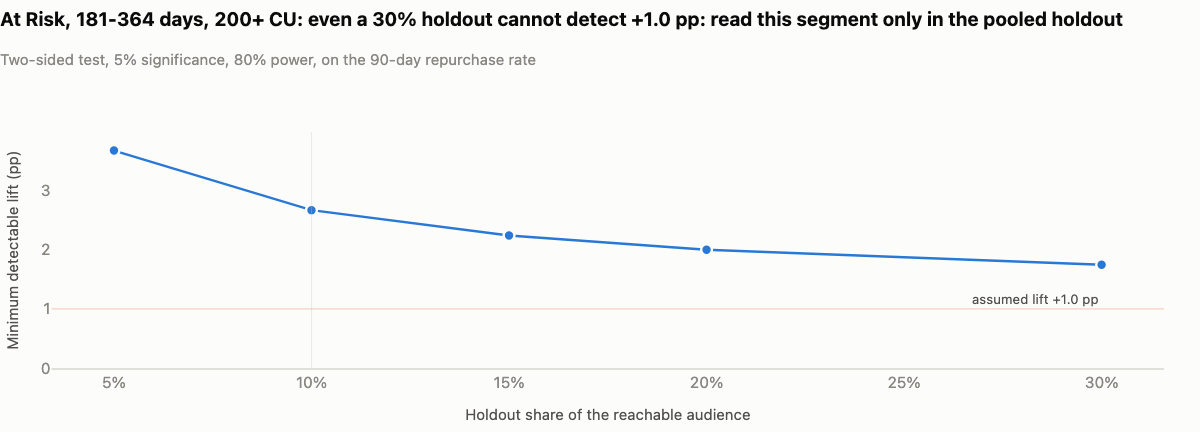

In [37]:
C.mde_by_holdout(D.mart("holdout_power"), "at_risk_181_364_high", 1.0, 0.10)

**Takeaway:** For the long-lapsed At Risk customers spending 200+ CU, even a 30% holdout could not detect the +1.0 pp assumed for
content (1.74 pp at 30%), so a bigger holdout would give up profit without buying a readable result; this audience is read in the
pooled holdout. The curve treats every non-holdout customer as one treated group (2.66 pp at 10%), so it sits slightly below the
per-arm figures in the table.

## Limitations

- **Store purchases are only visible for identified members**, so "online only" means "no identified store purchase"; some
  online-only customers also shop anonymously in store.
- **Gross demand only.** The data has no returns, and fashion returns are typically higher online, so online-vs-store value
  comparisons are before returns (the 25% / 8% haircut above is illustrative).
- **"If we do nothing" assumes customers behave like last year's look-alikes.** Autumn 2020 follows a store closure no backtest
  year contains (60% of At Risk last bought in March-May 2020), and a second closure would hit store-heavy customers harder than any
  scenario here. The delta-method interval covers sampling noise only; quote the scenario range.
- **The gap vs usual pace is not recoverable revenue.** Part of every gap is regression to the mean; the plan's incremental revenue
  is the number to promise, and it is itself an assumption until the holdout reads.
- **The economics are planning assumptions:** lifts, the 40% contribution margin (H&M gross margin 52.6% in FY2019 and 49.4% in the first half of 2020,
  less about 10 pp for fulfilment and returns; to confirm with Finance), coupon use by would-be buyers (50%) and contact costs. Valuing an
  incremental buyer at one order is deliberately conservative.
- **Segment sizes depend on where the lines are drawn.** Moving one group of thresholds by 25% changes the narrow segments a lot (At
  Risk grows 73% if "used to buy often" starts at 2 orders), which is why the thresholds are frozen and changed only with sign-off.
- **Category affinity reflects when a segment last bought**, not a fixed taste; the At Risk split above is an example.
- **Order = customer × day × channel**, so same-day online orders collapse into one and order counts are slightly understated.

## Recommendations / next step

**The plan in plain words** (all audiences re-scored with the same SQL on launch day, 2020-09-28):

- **Champions (190K): keep them without discounting.** Personal 48-hour early access to the autumn collection on 2020-09-29 and free
  click-and-collect on that order. No % discount: 83% buy within 90 days anyway.
- **Loyal (34K): build the basket.** "Complete your order" picks (accessories, basics multipacks) and a free-delivery threshold
  reminder from week 2. No discount, never paid media.
- **Slipping Regulars (62K): catch them early.** "New in for autumn" picks from the categories each customer bought most in week 1,
  reminder on day 10; candidate for an always-on trigger if the lift is positive at day 90.
- **Potential Loyalists (125K): build the habit** with "complete the look" recommendations from the last order's category.
- **New Customers (71K): win the second order** with a 3-email welcome journey from day 7 (email plus paid social for the two thirds
  not on email). 10% off the second order runs only in a test cell.
- **Needs Attention (138K): bridge summer to autumn** with a new-arrivals edit in week 1 and a reminder in week 3.
- **At Risk (90K): win back with content.** Email only for the 121-180-day group and for the 181-364-day group under 200 CU; email
  plus paid social for the 181-364-day group spending 200+ CU. 10% off one order runs only in a test cell; 20% off was considered
  and is not run. The 121-180-day email leads with each customer's own top categories (that group last bought during the spring closure);
  knitwear / outerwear lead only for the 181-364-day audiences.
- **Lost (369K): one reactivation email** in week 4 leading with kids' autumn and menswear, suppressed from paid media;
  non-responders move to a quarterly cadence.
- **Hibernating (284K): one 'new season' email** in week 4, with the Lost email, leading with underwear and nightwear; no paid
  media, no discount.
- **Review List (864): no offers or paid media** until CRM / retail ops have reviewed it.
- **Measure it** against the 10% holdout in every audience, decide on day 90 (2020-12-27), and scale an offer only if the 95% lower
  bound of its lift over the content cell clears its break-even.

**Next steps:** confirm the 40% contribution margin with Finance before the brief is locked; brief the CRM team on the two At Risk creatives; check that the kids' autumn range can carry the Lost email; re-run the migration view every month.

In [38]:
nbsetup.done()